**Linear LogReg probe PCA on English 5000 data ONLY ON MBERT, new surprise and fear w/o emojis and clean code and BRIGHTER+XED English + German test set + mDeBERTa, with BALANCED calibration AND (printed) PROBE WEIGHTS! ALSO ADDED EVALUATION TO PROJECTION METHODS (+ probe). Additional German calibration and a 6D classifier + probe training on hand labeled data. Estonian is smaller. CORRECT ONE!!**

In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_FILE = "combined_arabic_balanced_1200_new_bestest_no_@_1041_laughing.csv"
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42

In [3]:
# Pooling

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    summed = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    counts = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return summed / counts

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

In [4]:
# Encoding
def encode_texts(text_list, tokenizer, model, device, batch_size=32, max_length=128):
    mean_embs = []
    cls_embs = []

    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size), desc="Encoding"):
            batch_texts = text_list[i:i + batch_size]

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            encoded = {k: v.to(device) for k, v in encoded.items()}

            outputs = model(**encoded)

            mean_emb = mean_pooling(outputs, encoded["attention_mask"])
            cls_emb = cls_pooling(outputs)

            mean_embs.append(mean_emb.cpu().numpy())
            cls_embs.append(cls_emb.cpu().numpy())

    return np.vstack(mean_embs), np.vstack(cls_embs)

In [5]:
# Centroids

def compute_centroids(embeddings, df, emotion_order):
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(embeddings[mask].mean(axis=0))
    centroids = np.vstack(centroids)
    return normalize(centroids, norm="l2")

In [6]:
# PCA

def plot_centroids_in_full_pca_2d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=160)
        plt.text(
            centroids_2d[i, 0],
            centroids_2d[i, 1],
            emotion,
            fontsize=11,
            ha='center',
            va='center'
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

def plot_centroids_in_full_pca_3d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_3d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(emotion_order):
        ax.scatter(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            s=140
        )
        ax.text(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            emotion,
            fontsize=11
        )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

In [7]:
# Probe training
def train_probe(embeddings, labels, name):
    X_train, X_test, y_train, y_test = train_test_split(
        embeddings,
        labels,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=labels
    )

    clf = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    print(f"\n=== {name} probe ===")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
    print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))
    print(classification_report(y_test, y_pred, digits=3))

    return clf

In [8]:
# Linear probe PCA
def get_probe_space(probe, embeddings, use_probabilities=False):
    if use_probabilities:
        return probe.predict_proba(embeddings)
    else:
        scores = probe.decision_function(embeddings)

        if scores.ndim == 1:
            scores = scores[:, None]

        return scores


def plot_probe_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            label=emotion,
            alpha=0.35,
            s=10
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


def plot_probe_centroids_pca_2d(probe, embeddings, df, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    # centroid in probe space
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(probe_space[mask].mean(axis=0))
    centroids = np.vstack(centroids)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(probe_space)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    dx = (centroids_2d[:, 0].max() - centroids_2d[:, 0].min()) * 0.02
    dy = (centroids_2d[:, 1].max() - centroids_2d[:, 1].min()) * 0.02

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=180)
        plt.text(
            centroids_2d[i, 0] + dx,
            centroids_2d[i, 1] + dy,
            emotion,
            fontsize=11
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


def plot_probe_kde_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=True):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    # scatter lightly underneath
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            alpha=0.08,
            s=8,
            label=emotion
        )

    # KDE contours if seaborn is available
    try:
        import seaborn as sns

        for emotion in emotion_order:
            mask = (np.array(labels) == emotion)
            sns.kdeplot(
                x=X_2d[mask, 0],
                y=X_2d[mask, 1],
                levels=[0.25, 0.5],
                linewidths=2
            )
    except ImportError:
        print("seaborn not installed, showing scatter only.")

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [9]:
# Example prediction
example_texts = [
    "I am so happy and excited about this!",
    "This is disgusting and makes me sick.",
    "I am terrified something bad will happen.",
    "I miss you so much and feel empty.",
    "What a wonderful surprise!",
    "I am furious and cannot stand this anymore."
]

def predict_examples(text_list, tokenizer, model, device, probe, use_mean=True):
    mean_embs, cls_embs = encode_texts(
        text_list, tokenizer, model, device,
        batch_size=8, max_length=MAX_LENGTH
    )

    embs = mean_embs if use_mean else cls_embs
    embs = normalize(embs, norm="l2")

    preds = probe.predict(embs)
    probs = probe.predict_proba(embs)

    for text, pred, prob in zip(text_list, preds, probs):
        top_idx = np.argsort(prob)[::-1][:3]
        top3 = [(probe.classes_[i], round(float(prob[i]), 3)) for i in top_idx]

        print("\nTEXT:", text)
        print("Predicted:", pred)
        print("Top-3:", top3)

In [10]:

# Probe weight analysis

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    if not hasattr(probe, "coef_"):
        raise ValueError("Probe does not expose coef_. This works for LogisticRegression.")
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def plot_probe_weight_cosine_similarity(probe, class_order, title):
    W = get_probe_weight_matrix(probe)
    sim = cosine_similarity(W)
    sim_df = pd.DataFrame(sim, index=class_order, columns=class_order).round(3)

    print(f"\n{title}")
    print(sim_df)

    plt.figure(figsize=(7, 6))
    plt.imshow(sim, interpolation="nearest")
    plt.xticks(range(len(class_order)), class_order, rotation=45, ha="right")
    plt.yticks(range(len(class_order)), class_order)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return sim_df


def plot_probe_weights_pca_2d(probe, class_order, title):
    """
    PCA on probe weight vectors themselves.
    Each point = one emotion direction.
    """
    W = get_probe_weight_matrix(probe)

    # with few classes, max possible rank is limited
    n_comp = min(2, W.shape[0], W.shape[1])
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    W_2d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(class_order):
        plt.scatter(W_2d[i, 0], W_2d[i, 1], s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], emotion, fontsize=11)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, pca


def plot_probe_weights_pca_3d(probe, class_order, title):
    W = get_probe_weight_matrix(probe)

    n_comp = min(3, W.shape[0], W.shape[1])
    if n_comp < 3:
        print(f"\n{title}")
        print("Not enough dimensions/classes for 3D PCA.")
        return None, None

    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    W_3d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    # 🔽 ADD THIS BLOCK
    print("\n3D PCA coordinates (per emotion):")
    coords_df = pd.DataFrame(W_3d, columns=["PC1", "PC2", "PC3"])
    coords_df["emotion"] = class_order
    print(coords_df.round(4).to_string(index=False))

    # Also print in Desmos-friendly format
    print("\nDesmos-friendly format:")
    for i, emotion in enumerate(class_order):
        x, y, z = W_3d[i]
        print(f"{emotion}: ({x:.4f}, {y:.4f}, {z:.4f})")

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(class_order):
        ax.scatter(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], s=160)
        ax.text(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], emotion, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

    return W_3d, pca


def plot_probe_weights_vs_centroids_pca_2d(probe, centroids, class_order, title):
    """
    Compare probe weight vectors and class centroids in the same PCA space.
    PCA is fit on the combined matrix [weights; centroids].
    """
    W = get_probe_weight_matrix(probe)
    C = normalize(centroids.copy(), norm="l2")

    combined = np.vstack([W, C])

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    combined_2d = pca.fit_transform(combined)

    W_2d = combined_2d[:len(class_order)]
    C_2d = combined_2d[len(class_order):]

    print(f"\n{title}")
    print("Combined shape:", combined.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    for i, emotion in enumerate(class_order):
        # weights
        plt.scatter(W_2d[i, 0], W_2d[i, 1], marker="^", s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], f"{emotion}_W", fontsize=10)

        # centroids
        plt.scatter(C_2d[i, 0], C_2d[i, 1], marker="o", s=180)
        plt.text(C_2d[i, 0], C_2d[i, 1], f"{emotion}_C", fontsize=10)

        # line connecting them
        plt.plot(
            [W_2d[i, 0], C_2d[i, 0]],
            [W_2d[i, 1], C_2d[i, 1]],
            linestyle="--",
            alpha=0.5
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, C_2d, pca


def plot_probe_weight_projection_histograms(probe, embeddings, labels, emotion_order, title_prefix):
    """
    For each emotion direction, project all embeddings onto that weight vector.
    This shows whether the corresponding class tends to score higher along its own direction.
    """
    W = get_probe_weight_matrix(probe)
    X = normalize(embeddings.copy(), norm="l2")
    label_array = np.array(labels)

    for i, emotion in enumerate(emotion_order):
        scores = X @ W[i]

        plt.figure(figsize=(8, 5))
        for e in emotion_order:
            mask = label_array == e
            plt.hist(scores[mask], bins=40, alpha=0.35, label=e, density=True)

        plt.title(f"{title_prefix}: projection onto '{emotion}' weight")
        plt.xlabel("Cosine-like projection score")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(alpha=0.2)
        plt.show()

In [11]:

# Projection-based classifiers

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def predict_with_weight_cosine(embeddings, probe, class_order):
    """
    Classify by cosine similarity between embeddings and probe weight vectors.
    """
    X = normalize(embeddings.copy(), norm="l2")
    W = get_probe_weight_matrix(probe)  # already normalized

    scores = X @ W.T   # cosine-like similarity since both normalized
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def predict_with_prototypes(embeddings, centroids, class_order):
    """
    Classify by nearest normalized class centroid (cosine similarity).
    """
    X = normalize(embeddings.copy(), norm="l2")
    C = normalize(centroids.copy(), norm="l2")

    scores = X @ C.T
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def evaluate_simple_classifier(gold_labels, preds, scores, class_order, name="Classifier"):
    """
    Evaluation for cosine / prototype classifiers.
    Uses softmax(scores) as pseudo-probabilities for log loss + confidence stats.
    """
    probs = softmax_np(scores)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "scores": scores,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }
    
def predict_with_linear_scores(embeddings, probe, class_order, normalize_inputs=False):
    """
    Classify using the probe's raw linear scoring function:
        score_c = x · w_c + b_c

    If normalize_inputs=True, embeddings are L2-normalized first.
    This is still interpretable, but closer to the original logistic probe
    than cosine similarity to normalized weights.
    """
    X = embeddings.copy()
    if normalize_inputs:
        X = normalize(X, norm="l2")

    W = probe.coef_          # shape: (n_classes, dim)
    b = probe.intercept_     # shape: (n_classes,)

    scores = X @ W.T + b
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores

In [12]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def fit_bias_only(X_calib, y_calib, probe, class_order, l2=0.01):
    """
    Freeze probe weights W, learn only bias b on calibration data.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}
    y_idx = np.array([label_to_idx[y] for y in y_calib])

    def objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(np.log(probs[np.arange(len(y_idx)), y_idx] + 1e-12))

        # regularize toward original bias, so calibration does not overfit too much
        penalty = l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    result = minimize(
        objective,
        x0=old_b,
        method="BFGS"
    )

    return result.x


def predict_with_fixed_weights_new_bias(X, probe, new_b, class_order):
    W = probe.coef_.copy()
    scores = X @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, probs, scores


def evaluate_bias_calibrated(X_test, y_test, probe, new_b, class_order, name):
    preds, probs, scores = predict_with_fixed_weights_new_bias(
        X_test,
        probe,
        new_b,
        class_order
    )
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "scores": scores,
        "confusion_matrix": cm_df
    }

In [13]:
# mBERT loading

MODEL_NAME = "google-bert/bert-base-multilingual-cased"

df = pd.read_csv(DATA_FILE)
df["text"] = df["text"].astype(str)
df["emotion"] = df["emotion"].astype(str)

texts = df["text"].tolist()
labels = df["emotion"].tolist()
emotion_order = sorted(df["emotion"].unique())

print("Rows:", len(df))
print("Emotions:", emotion_order)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

Rows: 6246
Emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(119547, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropo

In [14]:
# mBERT info

# embeddings
mean_embeddings, cls_embeddings = encode_texts(
    texts, tokenizer, model, device,
    batch_size=BATCH_SIZE, max_length=MAX_LENGTH
)

print("Mean embeddings shape:", mean_embeddings.shape)
print("CLS embeddings shape:", cls_embeddings.shape)

# normalization
mean_embeddings_norm = normalize(mean_embeddings, norm="l2")
cls_embeddings_norm = normalize(cls_embeddings, norm="l2")  

# centroids
mean_centroids = compute_centroids(mean_embeddings_norm, df, emotion_order)
cls_centroids = compute_centroids(cls_embeddings_norm, df, emotion_order)

# cos similarity
mean_centroid_cos = cosine_similarity(mean_centroids)
cls_centroid_cos = cosine_similarity(cls_centroids)

print("\nCosine similarity between mean-pooled centroids:")
print(pd.DataFrame(mean_centroid_cos, index=emotion_order, columns=emotion_order).round(3))

print("\nCosine similarity between CLS centroids:")
print(pd.DataFrame(cls_centroid_cos, index=emotion_order, columns=emotion_order).round(3))



Encoding: 100%|██████████| 196/196 [01:01<00:00,  3.18it/s]

Mean embeddings shape: (6246, 768)
CLS embeddings shape: (6246, 768)

Cosine similarity between mean-pooled centroids:
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.995  0.998  0.996    0.998     0.998
disgust   0.995    1.000  0.994  0.991    0.994     0.993
fear      0.998    0.994  1.000  0.995    0.999     0.998
joy       0.996    0.991  0.995  1.000    0.997     0.997
sadness   0.998    0.994  0.999  0.997    1.000     0.997
surprise  0.998    0.993  0.998  0.997    0.997     1.000

Cosine similarity between CLS centroids:
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.995  0.999  0.999    1.000     1.000
disgust   0.995    1.000  0.995  0.994    0.995     0.995
fear      0.999    0.995  1.000  0.999    1.000     1.000
joy       0.999    0.994  0.999  1.000    0.999     0.999
sadness   1.000    0.995  1.000  0.999    1.000     0.999
surprise  1.000    0.995  1.000  0.999    0.999     1.000



Emotion centroids projected into full mean-pooled PCA space
Explained variance ratio: [0.0847 0.0588]


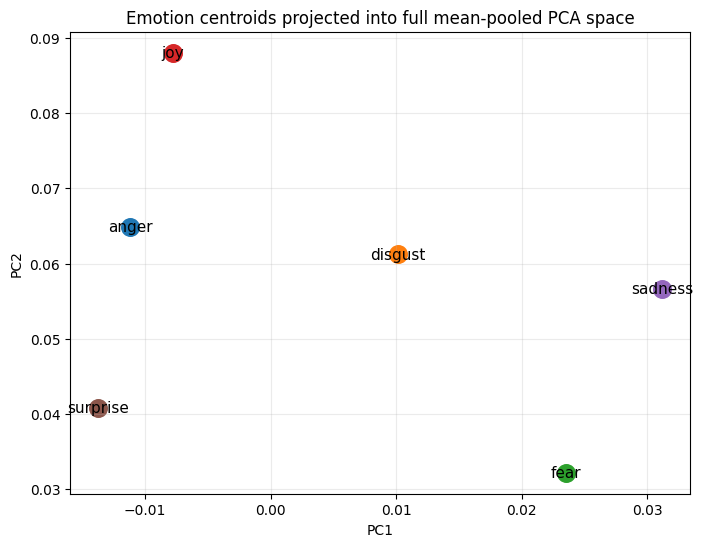


Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)
Explained variance ratio: [0.0847 0.0588 0.034 ]


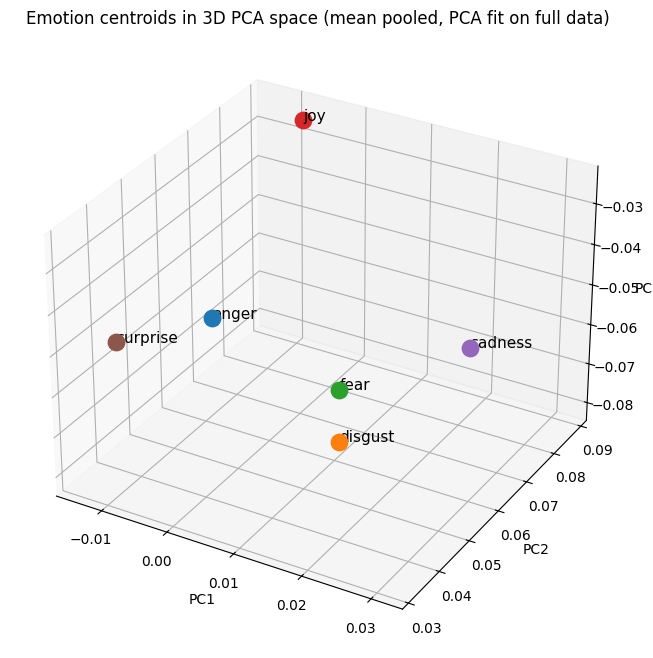


Emotion centroids projected into full CLS PCA space
Explained variance ratio: [0.2961 0.0833]


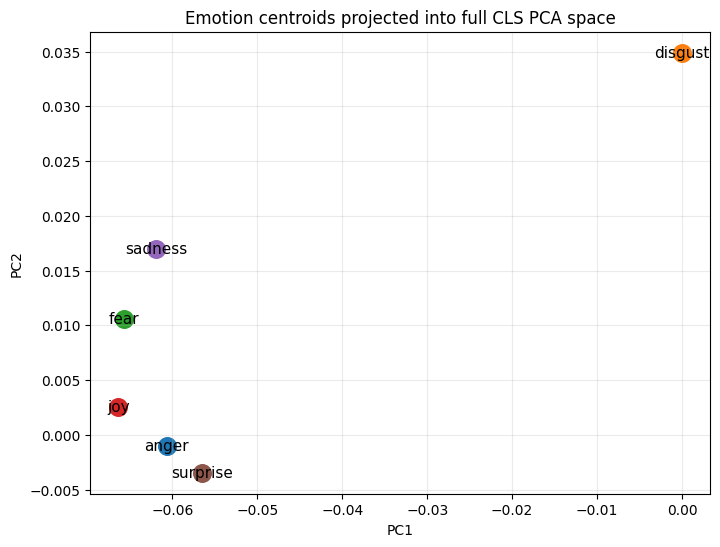

In [15]:
# mBERT visualizations

plot_centroids_in_full_pca_2d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids projected into full mean-pooled PCA space"
)

plot_centroids_in_full_pca_3d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)"
)

# Optional direct comparison with CLS
plot_centroids_in_full_pca_2d(
    cls_embeddings_norm,
    cls_centroids,
    emotion_order,
    "Emotion centroids projected into full CLS PCA space"
)


=== Mean-pooled probe ===
Accuracy: 0.3136
Balanced accuracy: 0.3136
Macro F1: 0.3008
Weighted F1: 0.3008
              precision    recall  f1-score   support

       anger      0.261     0.226     0.242       208
     disgust      0.407     0.577     0.477       208
        fear      0.280     0.269     0.275       208
         joy      0.371     0.455     0.409       209
     sadness      0.224     0.167     0.192       209
    surprise      0.239     0.188     0.210       208

    accuracy                          0.314      1250
   macro avg      0.297     0.314     0.301      1250
weighted avg      0.297     0.314     0.301      1250


=== CLS probe ===
Accuracy: 0.296
Balanced accuracy: 0.296
Macro F1: 0.2812
Weighted F1: 0.2812
              precision    recall  f1-score   support

       anger      0.247     0.212     0.228       208
     disgust      0.373     0.567     0.450       208
        fear      0.242     0.240     0.241       208
         joy      0.347     0.435   

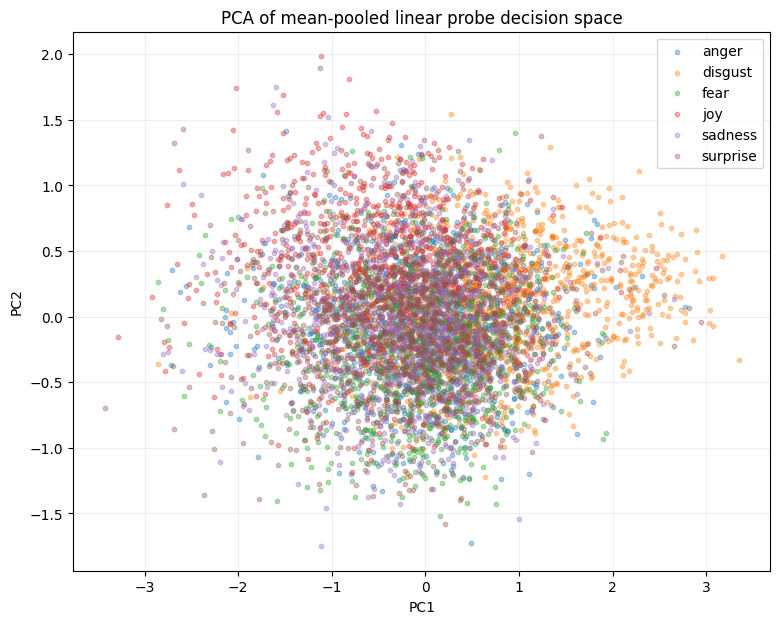


PCA of mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.5048 0.2055]


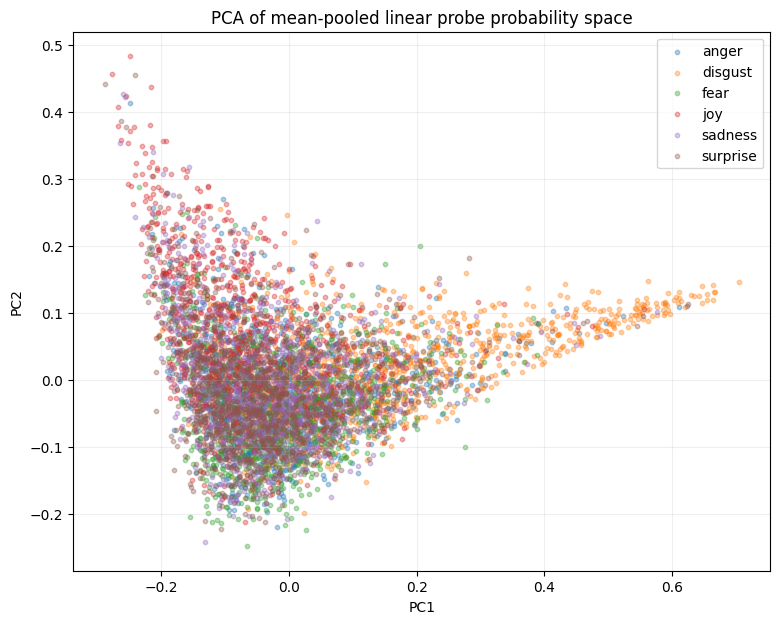


Emotion centroids in mean-pooled linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.5492 0.175 ]


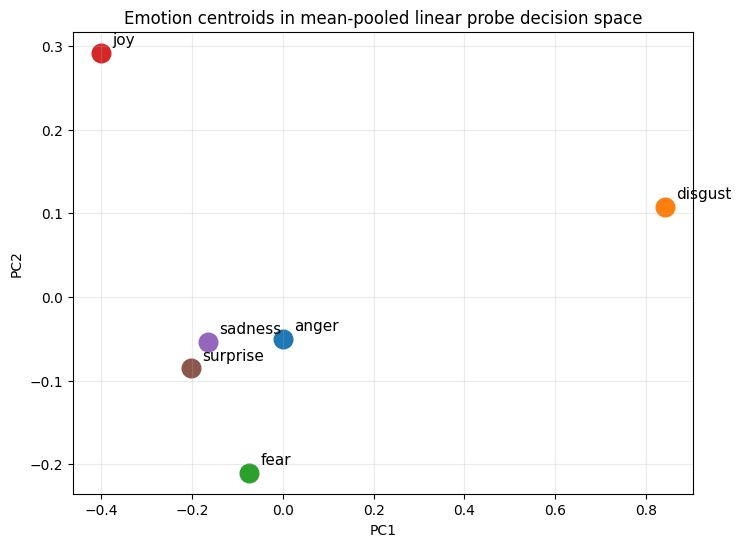


Emotion centroids in mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.5048 0.2055]


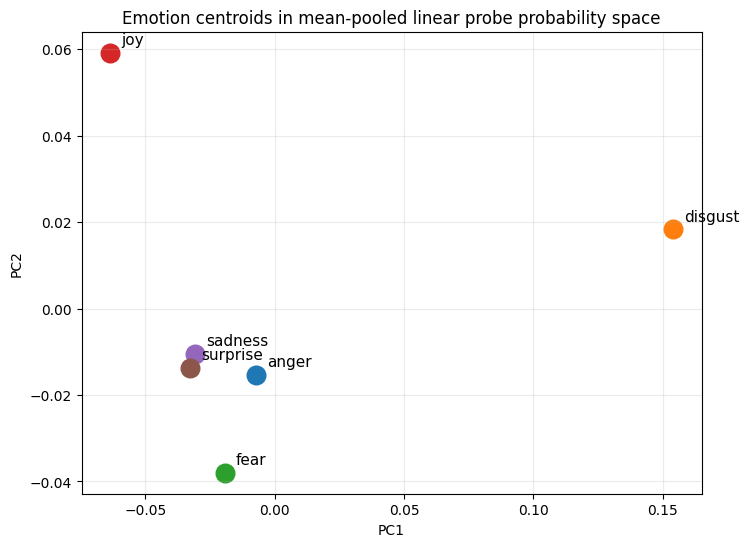


KDE contours of mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.5048 0.2055]


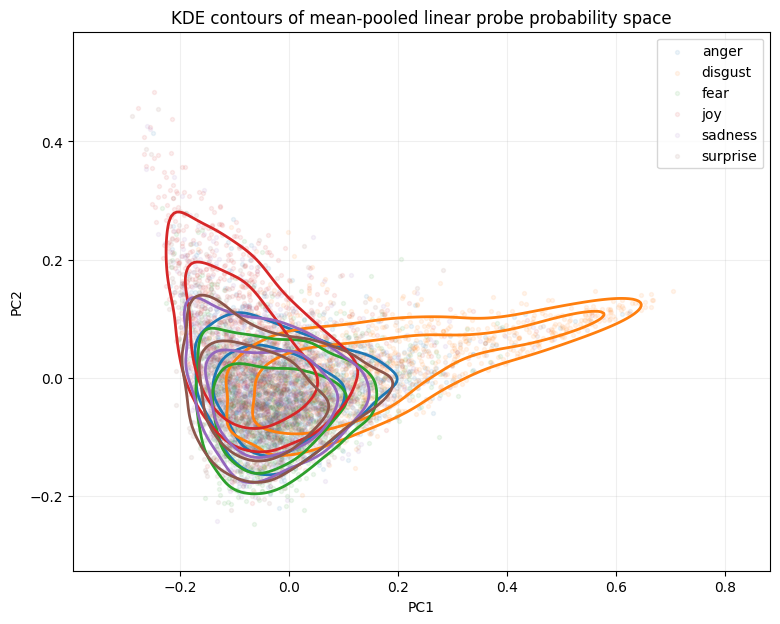


PCA of CLS linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6111 0.1625]


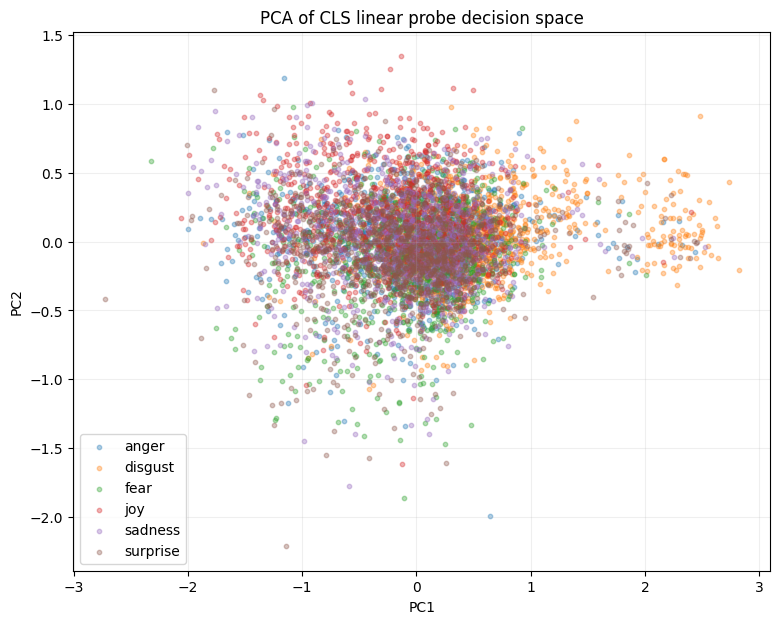


PCA of CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6066 0.1818]


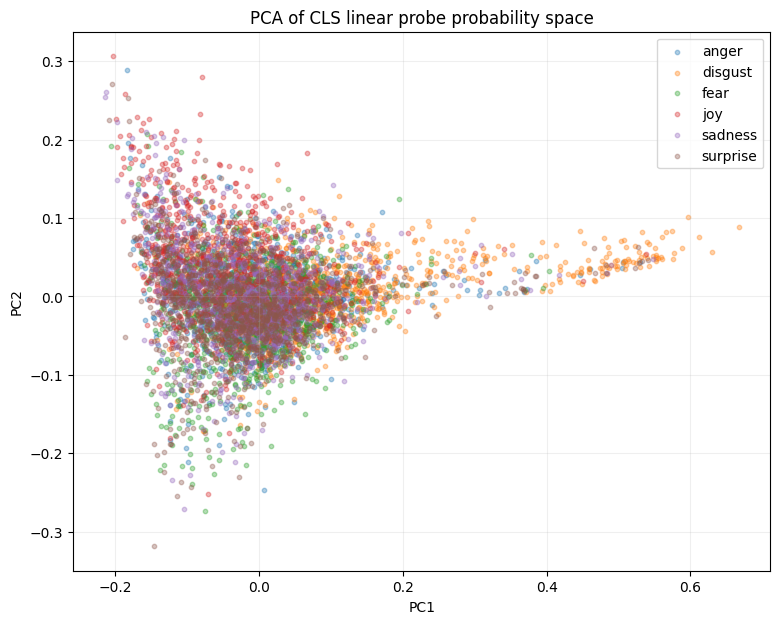


Emotion centroids in CLS linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6111 0.1625]


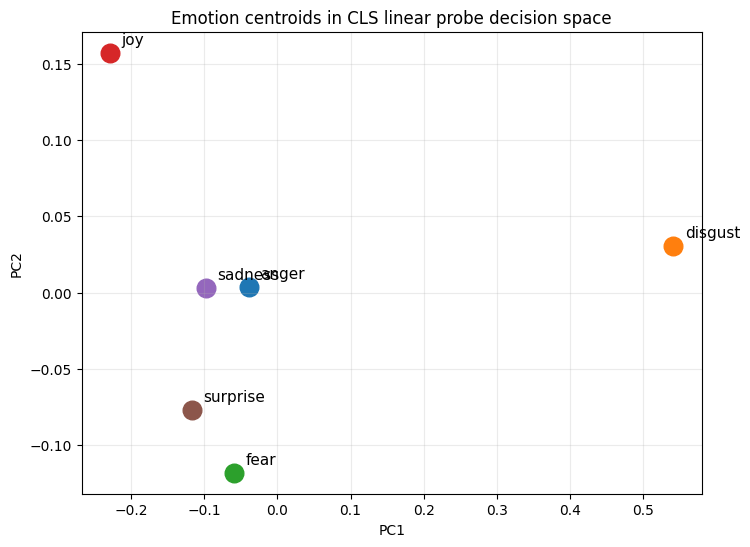


Emotion centroids in CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6066 0.1818]


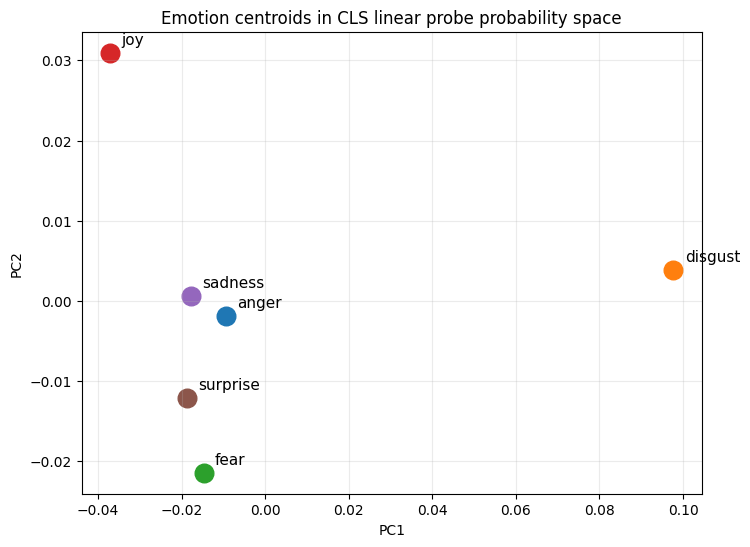


KDE contours of CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6066 0.1818]


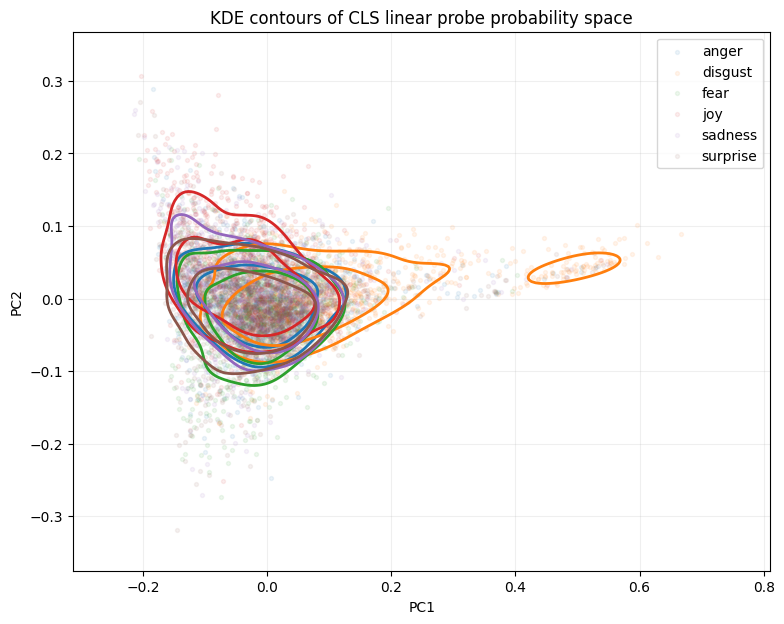

In [16]:
# probe training

mean_probe = train_probe(mean_embeddings_norm, labels, "Mean-pooled")
cls_probe = train_probe(cls_embeddings_norm, labels, "CLS")

# probe visualization

plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of mean-pooled linear probe probability space",
    use_probabilities=True
)

##### CLS!!!!!

# probe visualization

plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of CLS linear probe probability space",
    use_probabilities=True
)



Cosine similarity between mean-pooled probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000   -0.132 -0.128 -0.233   -0.090    -0.282
disgust  -0.132    1.000 -0.272 -0.385   -0.411    -0.239
fear     -0.128   -0.272  1.000 -0.226   -0.043    -0.096
joy      -0.233   -0.385 -0.226  1.000   -0.068    -0.076
sadness  -0.090   -0.411 -0.043 -0.068    1.000    -0.205
surprise -0.282   -0.239 -0.096 -0.076   -0.205     1.000


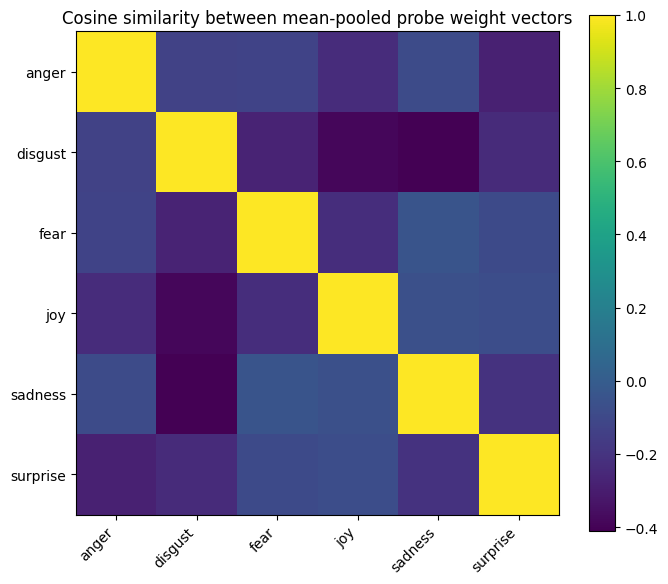


PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2586 0.2246]


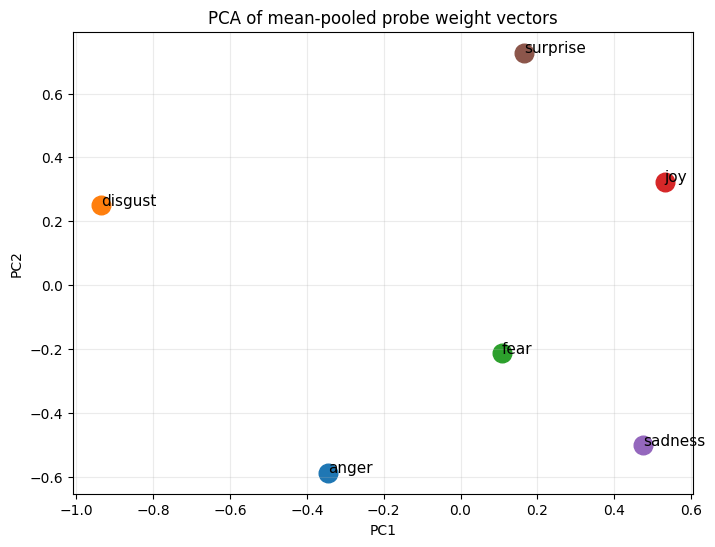


3D PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2586 0.2246 0.1995]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
-0.3453 -0.5874 -0.2822    anger
-0.9354  0.2504 -0.1296  disgust
 0.1082 -0.2140  0.7875     fear
 0.5314  0.3241 -0.6206      joy
 0.4755 -0.5008 -0.0473  sadness
 0.1656  0.7277  0.2922 surprise

Desmos-friendly format:
anger: (-0.3453, -0.5874, -0.2822)
disgust: (-0.9354, 0.2504, -0.1296)
fear: (0.1082, -0.2140, 0.7875)
joy: (0.5314, 0.3241, -0.6206)
sadness: (0.4755, -0.5008, -0.0473)
surprise: (0.1656, 0.7277, 0.2922)


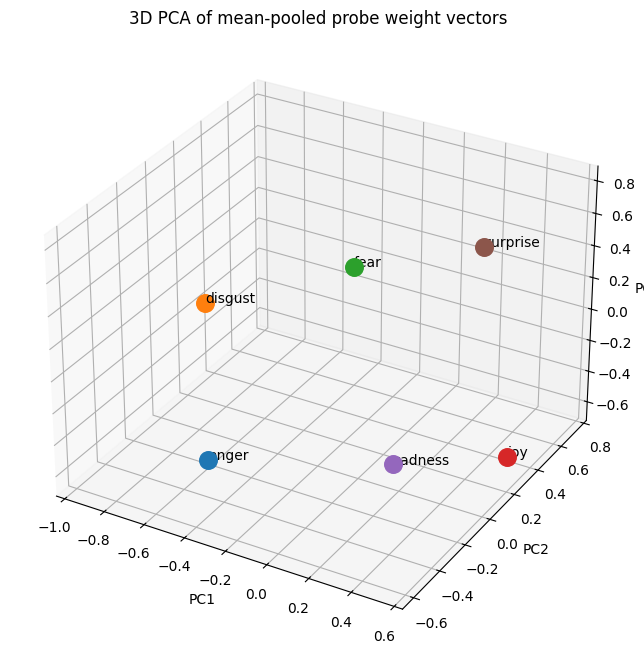


Mean-pooled probe weights vs mean-pooled class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3489 0.1674]


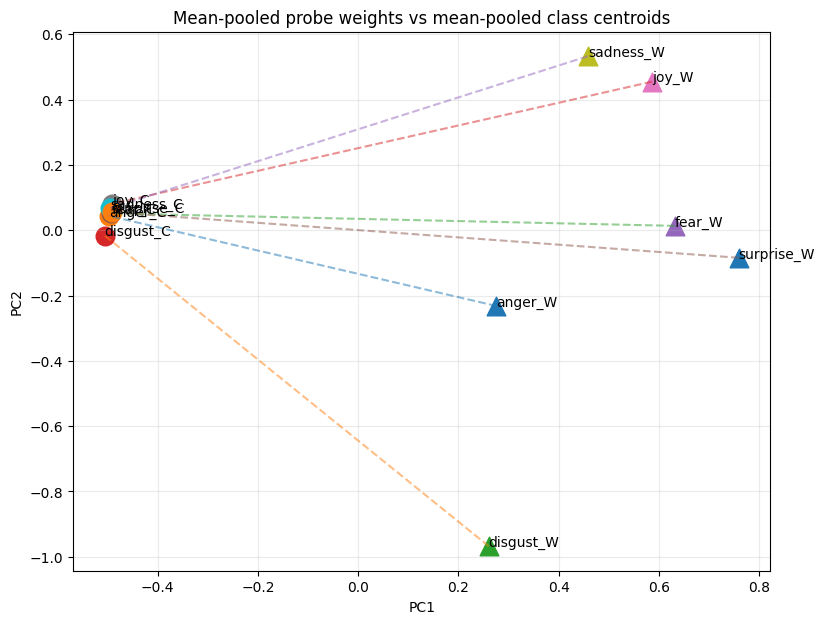


Cosine similarity between CLS probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000   -0.163 -0.072 -0.236   -0.082    -0.240
disgust  -0.163    1.000 -0.201 -0.423   -0.394    -0.347
fear     -0.072   -0.201  1.000 -0.351   -0.106    -0.012
joy      -0.236   -0.423 -0.351  1.000    0.045    -0.048
sadness  -0.082   -0.394 -0.106  0.045    1.000    -0.193
surprise -0.240   -0.347 -0.012 -0.048   -0.193     1.000


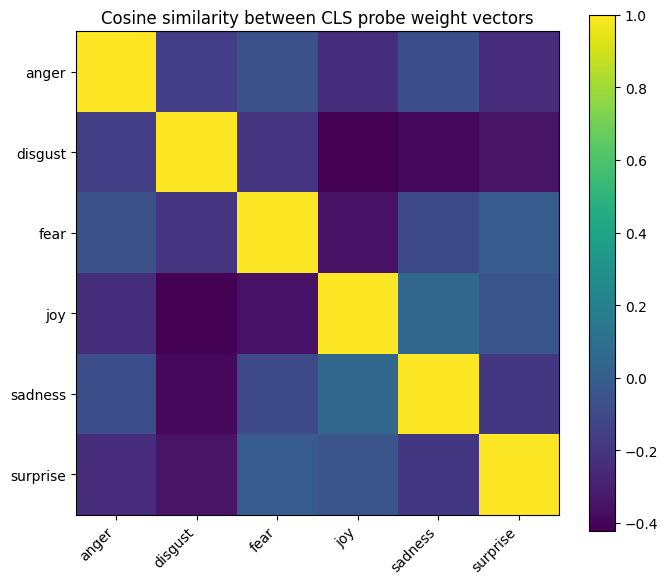


PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2765 0.2196]


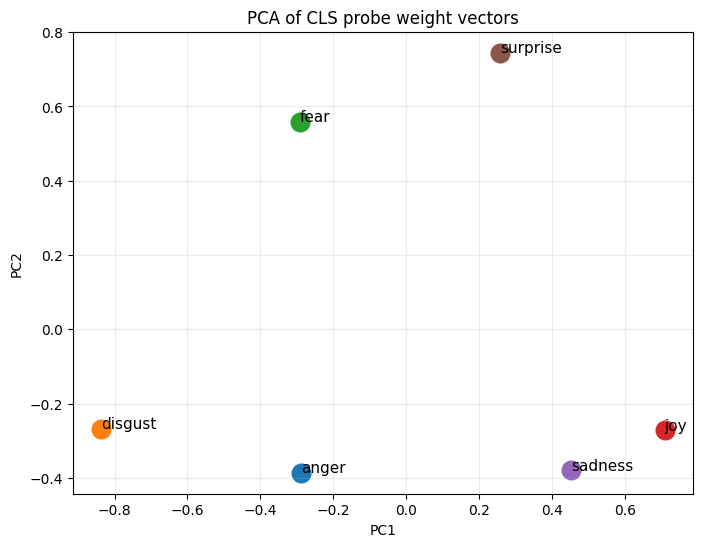


3D PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.2765 0.2196 0.2056]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
-0.2886 -0.3860  0.4831    anger
-0.8374 -0.2671 -0.5940  disgust
-0.2921  0.5590  0.4726     fear
 0.7090 -0.2713 -0.4388      joy
 0.4515 -0.3793  0.3673  sadness
 0.2576  0.7447 -0.2902 surprise

Desmos-friendly format:
anger: (-0.2886, -0.3860, 0.4831)
disgust: (-0.8374, -0.2671, -0.5940)
fear: (-0.2921, 0.5590, 0.4726)
joy: (0.7090, -0.2713, -0.4388)
sadness: (0.4515, -0.3793, 0.3673)
surprise: (0.2576, 0.7447, -0.2902)


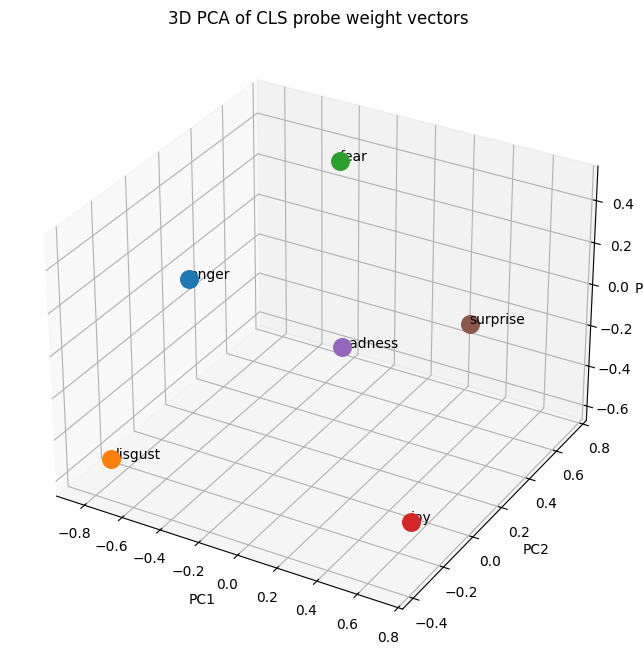


CLS probe weights vs CLS class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3407 0.1837]


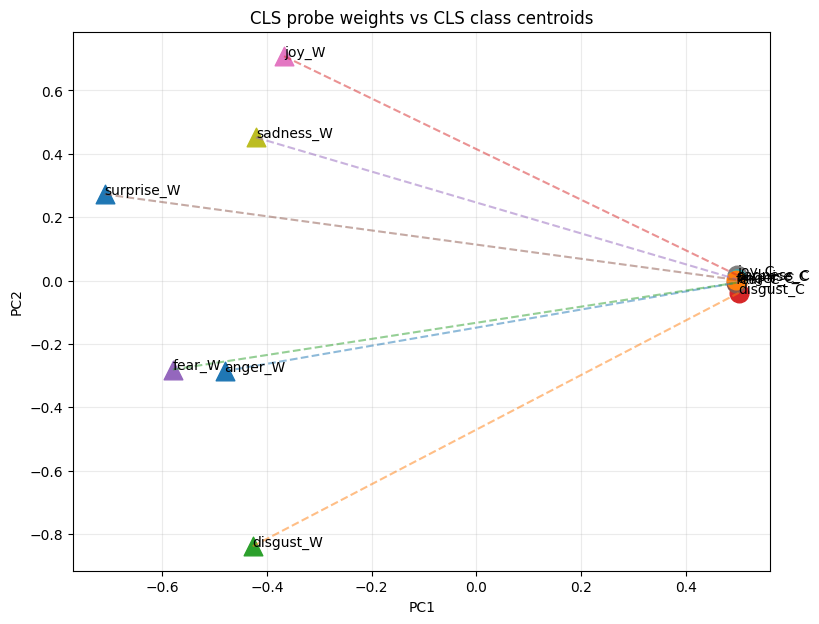

(array([[-0.48068311, -0.28554437],
        [-0.42710617, -0.83811697],
        [-0.57952975, -0.28046652],
        [-0.36711058,  0.70809194],
        [-0.42107394,  0.45186073],
        [-0.70979821,  0.2724401 ]]),
 array([[ 0.49747703, -0.00630914],
        [ 0.50072094, -0.03865509],
        [ 0.49579615, -0.00681697],
        [ 0.49820933,  0.01697718],
        [ 0.49754552,  0.00379517],
        [ 0.49555278,  0.00274395]]),
 PCA(n_components=2, random_state=42))

In [17]:

# Probe weight analysis

class_order = list(mean_probe.classes_)

# Mean-pooled probe weights
plot_probe_weight_cosine_similarity(
    mean_probe,
    class_order,
    "Cosine similarity between mean-pooled probe weight vectors"
)

plot_probe_weights_pca_2d(
    mean_probe,
    class_order,
    "PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_pca_3d(
    mean_probe,
    class_order,
    "3D PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    mean_probe,
    mean_centroids,
    class_order,
    "Mean-pooled probe weights vs mean-pooled class centroids"
)


# CLS probe weights
plot_probe_weight_cosine_similarity(
    cls_probe,
    class_order,
    "Cosine similarity between CLS probe weight vectors"
)

plot_probe_weights_pca_2d(
    cls_probe,
    class_order,
    "PCA of CLS probe weight vectors"
)

plot_probe_weights_pca_3d(
    cls_probe,
    class_order,
    "3D PCA of CLS probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    cls_probe,
    cls_centroids,
    class_order,
    "CLS probe weights vs CLS class centroids"
)

In [18]:
# example prediction and t-sne


print("\n--- Example predictions with mean-pooled probe ---")
predict_examples(example_texts, tokenizer, model, device, mean_probe, use_mean=True)

print("\n--- Example predictions with CLS probe ---")
predict_examples(example_texts, tokenizer, model, device, cls_probe, use_mean=False)

X_tsne_input = mean_embeddings_norm
y_tsne = df["emotion"].values


--- Example predictions with mean-pooled probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00,  3.79it/s]



TEXT: I am so happy and excited about this!
Predicted: surprise
Top-3: [('surprise', 0.327), ('joy', 0.323), ('fear', 0.252)]

TEXT: This is disgusting and makes me sick.
Predicted: fear
Top-3: [('fear', 0.508), ('joy', 0.156), ('sadness', 0.145)]

TEXT: I am terrified something bad will happen.
Predicted: fear
Top-3: [('fear', 0.328), ('joy', 0.268), ('surprise', 0.197)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.429), ('fear', 0.27), ('sadness', 0.156)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.446), ('joy', 0.303), ('fear', 0.178)]

TEXT: I am furious and cannot stand this anymore.
Predicted: fear
Top-3: [('fear', 0.328), ('joy', 0.296), ('sadness', 0.165)]

--- Example predictions with CLS probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00, 50.80it/s]


TEXT: I am so happy and excited about this!
Predicted: surprise
Top-3: [('surprise', 0.379), ('joy', 0.243), ('fear', 0.232)]

TEXT: This is disgusting and makes me sick.
Predicted: fear
Top-3: [('fear', 0.298), ('sadness', 0.242), ('joy', 0.17)]

TEXT: I am terrified something bad will happen.
Predicted: joy
Top-3: [('joy', 0.298), ('sadness', 0.237), ('fear', 0.2)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.372), ('sadness', 0.245), ('fear', 0.166)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.452), ('fear', 0.222), ('joy', 0.201)]

TEXT: I am furious and cannot stand this anymore.
Predicted: joy
Top-3: [('joy', 0.313), ('fear', 0.248), ('sadness', 0.192)]


In [19]:
from datasets import load_dataset
import pandas as pd

target_emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
random_state = 42

# =====================================================
# 1. LOAD BRIGHTER
# =====================================================
dfs = []

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "arq",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df = pd.concat(dfs, ignore_index=True)
brighter_df["text"] = brighter_df["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df.columns:
        brighter_df[col] = 0
    brighter_df[col] = brighter_df[col].fillna(0).astype(int)

# keep only single-label
brighter_df["n_active"] = brighter_df[target_emotions].sum(axis=1)
brighter_df = brighter_df[brighter_df["n_active"] == 1].copy()

# convert to single label
brighter_df["emotion"] = brighter_df[target_emotions].idxmax(axis=1)

brighter_df = brighter_df[["text", "emotion"]]

print("\nBRIGHTER distribution:")
print(brighter_df["emotion"].value_counts())


# second arabic

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "ary",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df_2 = pd.concat(dfs, ignore_index=True)
brighter_df_2["text"] = brighter_df_2["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df_2.columns:
        brighter_df_2[col] = 0
    brighter_df_2[col] = brighter_df_2[col].fillna(0).astype(int)

# keep only single-label
brighter_df_2["n_active"] = brighter_df_2[target_emotions].sum(axis=1)
brighter_df_2 = brighter_df_2[brighter_df_2["n_active"] == 1].copy()

# convert to single label
brighter_df_2["emotion"] = brighter_df_2[target_emotions].idxmax(axis=1)

brighter_df_2 = brighter_df_2[["text", "emotion"]]

print("\nBRIGHTER distribution 2:")
print(brighter_df_2["emotion"].value_counts())


# # =====================================================
# # 2. LOAD GOEMOTIONS (your CSV)
# # =====================================================
# go_df = pd.read_csv("goemotions_German.csv")

# go_df["text"] = go_df["text"].astype(str)
# go_df["emotion"] = go_df["emotion"].astype(str)

# # keep only target emotions (important!)
# go_df = go_df[go_df["emotion"].isin(target_emotions)]

# print("\nGoEmotions distribution:")
# print(go_df["emotion"].value_counts())


# =====================================================
# 2.1 LOAD XED (your CSV)
# =====================================================
xed_df = pd.read_csv("xed_arabic.csv")

xed_df["text"] = xed_df["text"].astype(str)
xed_df["emotion"] = xed_df["emotion"].astype(str)

# keep only target emotions (important!)
xed_df = xed_df[xed_df["emotion"].isin(target_emotions)]

print("\XED distribution:")
print(xed_df["emotion"].value_counts())


# =====================================================
# 3. COMBINE
# =====================================================
comb_df = pd.concat([brighter_df, brighter_df_2, xed_df], ignore_index=True)

print("\nCombined distribution BEFORE balancing:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 4. BALANCE
# =====================================================
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []

for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced rows:", len(comb_df))
print("\nBalanced distribution:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 5. FINAL OUTPUT
# =====================================================
xed_texts = comb_df["text"].tolist()
xed_labels = comb_df["emotion"].tolist()


xed_mean_embeddings, xed_cls_embeddings = encode_texts(
    xed_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

xed_mean_embeddings_norm = normalize(xed_mean_embeddings, norm="l2")
xed_cls_embeddings_norm = normalize(xed_cls_embeddings, norm="l2")

print("\nXED mean embeddings shape:", xed_mean_embeddings_norm.shape)
print("XED CLS embeddings shape:", xed_cls_embeddings_norm.shape)

print("\nMean probe classes:", mean_probe.classes_)
print("CLS probe classes:", cls_probe.classes_)

class_order = list(mean_probe.classes_)

# Split df into calibration and test
mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    xed_mean_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    xed_cls_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)



print("\nCalibration set size:", len(y_calib))
print("Test set size:", len(y_test))



# Evaluation stats
def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in gold_labels])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }


# Baseline: uncalibrated
mean_base_results = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled mBERT (uncalibrated)"
)


BRIGHTER distribution:
emotion
sadness     331
joy         230
surprise    202
anger       130
fear         59
disgust      28
Name: count, dtype: int64

BRIGHTER distribution 2:
emotion
joy         906
anger       806
sadness     663
surprise    626
fear        189
disgust      66
Name: count, dtype: int64
\XED distribution:
emotion
anger       518
surprise    282
fear        276
sadness     244
joy         216
disgust     165
Name: count, dtype: int64

Combined distribution BEFORE balancing:
emotion
anger       1454
joy         1352
sadness     1238
surprise    1110
fear         524
disgust      259
Name: count, dtype: int64

Balanced rows: 1554

Balanced distribution:
emotion
surprise    259
disgust     259
joy         259
anger       259
sadness     259
fear        259
Name: count, dtype: int64


Encoding: 100%|██████████| 49/49 [00:12<00:00,  3.92it/s]


XED mean embeddings shape: (1554, 768)
XED CLS embeddings shape: (1554, 768)

Mean probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']
CLS probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']

Calibration set size: 777
Test set size: 777

=== Mean-pooled mBERT (uncalibrated) on XED test ===
Accuracy: 0.1557
Balanced accuracy: 0.1557
Macro F1: 0.1483
Weighted F1: 0.1483
Log loss: 1.921
Top-3 accuracy: 0.5084

Classification report:
              precision    recall  f1-score   support

       anger      0.148     0.132     0.139       129
     disgust      0.079     0.062     0.070       129
        fear      0.094     0.062     0.074       130
         joy      0.172     0.285     0.214       130
     sadness      0.211     0.177     0.192       130
    surprise      0.184     0.217     0.199       129

    accuracy                          0.156       777
   macro avg      0.148     0.156     0.148       777
weighted avg      0.148     0.156     0.148

In [20]:
# =====================================================
# HUMAN-LABEL FINE-TUNED PROBE
# =====================================================

from sklearn.linear_model import LogisticRegression

def train_eval_human_probe(X_calib, X_test, y_calib, y_test, class_order, name):
    human_probe = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    human_probe.fit(X_calib, y_calib)

    preds = human_probe.predict(X_test)
    probs = human_probe.predict_proba(X_test)

    print(f"\n=== {name}: probe trained on human calibration data ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    top_k = 3
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])
    top_k_acc = np.mean([gold_idx[i] in top_k_preds[i] for i in range(len(gold_idx))])
    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": human_probe,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_human_probe_results = train_eval_human_probe(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled"
)

cls_human_probe_results = train_eval_human_probe(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    class_order,
    name="CLS"
)


=== Mean-pooled: probe trained on human calibration data ===
Accuracy: 0.3604
Balanced accuracy: 0.3603
Macro F1: 0.3591
Weighted F1: 0.3591
Log loss: 1.6182
Top-3 accuracy: 0.7452

Classification report:
              precision    recall  f1-score   support

       anger      0.366     0.287     0.322       129
     disgust      0.370     0.395     0.382       129
        fear      0.246     0.246     0.246       130
         joy      0.441     0.400     0.419       130
     sadness      0.347     0.469     0.399       130
    surprise      0.412     0.364     0.387       129

    accuracy                          0.360       777
   macro avg      0.364     0.360     0.359       777
weighted avg      0.364     0.360     0.359       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        37       21    28   22       10        11
disgust      12       51    27   11       18        10
fear         17       30    32    9       25        17
joy          

In [21]:
from sklearn.linear_model import LogisticRegression

# =====================================================
# 6D EMOTION SUBSPACE CLASSIFIER
# =====================================================

def project_to_probe_subspace(X, probe, use_bias=False):
    W = probe.coef_.copy()
    Z = X @ W.T

    if use_bias:
        Z = Z + probe.intercept_

    return Z


def train_eval_6d_classifier(X_calib, X_test, y_calib, y_test, probe, class_order, name, use_bias=False):
    Z_calib = project_to_probe_subspace(X_calib, probe, use_bias=use_bias)
    Z_test = project_to_probe_subspace(X_test, probe, use_bias=use_bias)

    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: Logistic Regression on 6D probe subspace ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "Z_calib": Z_calib,
        "Z_test": Z_test,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_6d_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_probe,
    class_order,
    name="Mean-pooled"
)

cls_6d_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_probe,
    class_order,
    name="CLS"
)


=== Mean-pooled: Logistic Regression on 6D probe subspace ===
6D train shape: (777, 6)
6D test shape: (777, 6)
Accuracy: 0.2561
Balanced accuracy: 0.256
Macro F1: 0.2489
Weighted F1: 0.249
Log loss: 1.7226

Classification report:
              precision    recall  f1-score   support

       anger      0.198     0.124     0.152       129
     disgust      0.245     0.287     0.264       129
        fear      0.182     0.169     0.175       130
         joy      0.328     0.438     0.375       130
     sadness      0.260     0.246     0.253       130
    surprise      0.276     0.271     0.273       129

    accuracy                          0.256       777
   macro avg      0.248     0.256     0.249       777
weighted avg      0.248     0.256     0.249       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        16       21    18   34       17        23
disgust       9       37    31   27       17         8
fear         14       38    22   16       1

In [22]:
mean_6d_human_probe_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_human_probe_results["model"],
    class_order,
    name="Mean-pooled human-probe 6D"
)

cls_6d_human_probe_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_human_probe_results["model"],
    class_order,
    name="CLS human-probe 6D"
)


=== Mean-pooled human-probe 6D: Logistic Regression on 6D probe subspace ===
6D train shape: (777, 6)
6D test shape: (777, 6)
Accuracy: 0.3514
Balanced accuracy: 0.3513
Macro F1: 0.3504
Weighted F1: 0.3504
Log loss: 1.7137

Classification report:
              precision    recall  f1-score   support

       anger      0.316     0.279     0.296       129
     disgust      0.373     0.388     0.380       129
        fear      0.260     0.246     0.253       130
         joy      0.465     0.408     0.434       130
     sadness      0.365     0.438     0.399       130
    surprise      0.331     0.349     0.340       129

    accuracy                          0.351       777
   macro avg      0.352     0.351     0.350       777
weighted avg      0.352     0.351     0.350       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        36       22    23   19       13        16
disgust      16       50    25    8       14        16
fear         22       26  

In [23]:
# =====================================================
# LABEL DISAGREEMENT / ERROR INSPECTION
# =====================================================

# Recreate split with indices so we can recover the original texts
all_indices = np.arange(len(comb_df))

mean_idx_calib, mean_idx_test, _, _ = train_test_split(
    all_indices,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

test_texts = comb_df.iloc[mean_idx_test]["text"].tolist()
test_gold = np.array(y_test)

def inspect_strong_disagreements(X_test, probe, test_texts, gold_labels, class_order, n=30, name="Probe"):
    probs = probe.predict_proba(X_test)
    preds = probe.predict(X_test)

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    rows = []

    for i in range(len(gold_labels)):
        if preds[i] != gold_labels[i]:
            top3_idx = np.argsort(probs[i])[::-1][:3]
            top3 = [(class_order[j], round(float(probs[i, j]), 3)) for j in top3_idx]

            rows.append({
                "text": test_texts[i],
                "gold": gold_labels[i],
                "pred": preds[i],
                "confidence": pred_conf[i],
                "top3": top3
            })

    err_df = pd.DataFrame(rows).sort_values("confidence", ascending=False)

    print(f"\n=== Strongest disagreements: {name} ===")
    print("Total errors:", len(err_df))

    for _, row in err_df.head(n).iterrows():
        print("\nTEXT:", row["text"])
        print("Gold:", row["gold"])
        print("Pred:", row["pred"])
        print("Confidence:", round(row["confidence"], 4))
        print("Top-3:", row["top3"])

    return err_df


mean_error_df = inspect_strong_disagreements(
    mean_X_test,
    mean_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="Mean-pooled probe"
)

cls_error_df = inspect_strong_disagreements(
    cls_X_test,
    cls_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="CLS probe"
)


=== Strongest disagreements: Mean-pooled probe ===
Total errors: 656

TEXT: شيءٌ أردت الحديث عنه فيتوجب علي اللجوء إليه.
Gold: fear
Pred: joy
Confidence: 0.5904
Top-3: [('joy', 0.59), ('sadness', 0.155), ('surprise', 0.1)]

TEXT: علاش لمغاربة كايمشيو لداعش؟ دراسة نفسية أمريكية لجذور لارهاب و التطرف
Gold: fear
Pred: disgust
Confidence: 0.5496
Top-3: [('disgust', 0.55), ('anger', 0.139), ('sadness', 0.093)]

TEXT: بعد مغادرة زوجته للتراب الوطني رفقة ابنته القاصر، مواطن مراكشي يراسل وزير العدل للتحقيق في تزوير وثائق رسمية
Gold: surprise
Pred: disgust
Confidence: 0.54
Top-3: [('disgust', 0.54), ('anger', 0.145), ('surprise', 0.122)]

TEXT: رحم الله الفنان العبقري الراحل عبـد الحــليم حافظ الذي قل نظيره في زمن الرداءة والتسيب المقصود والممنهج في وطننا لاكلمات لالحن يشفيان غليل ذوقنا اليتيم، فاقد الشيئ لايعطيه'
Gold: sadness
Pred: disgust
Confidence: 0.5279
Top-3: [('disgust', 0.528), ('anger', 0.14), ('surprise', 0.097)]

TEXT: أنا لا أفهم لِماذا إبنَي يَجِبُ أَنْ لا يحصل على حِصَّته الخاص

In [24]:

# Projection classifier: cosine to probe weights

mean_weight_preds, mean_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_weight_results = evaluate_simple_classifier(
    y_test,
    mean_weight_preds,
    mean_weight_scores,
    class_order,
    name="Mean-pooled XLM-R (cosine to probe weights)"
)

cls_weight_preds, cls_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_weight_results = evaluate_simple_classifier(
    y_test,
    cls_weight_preds,
    cls_weight_scores,
    class_order,
    name="CLS XLM-R (cosine to probe weights)"
)


# Prototype classifier: nearest centroid

mean_proto_preds, mean_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proto_preds,
    mean_proto_scores,
    class_order,
    name="Mean-pooled XLM-R (prototype classifier)"
)

cls_proto_preds, cls_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proto_preds,
    cls_proto_scores,
    class_order,
    name="CLS XLM-R (prototype classifier)"
)




=== Mean-pooled XLM-R (cosine to probe weights) on XED test ===
Accuracy: 0.1506
Balanced accuracy: 0.1509
Macro F1: 0.0911
Weighted F1: 0.0909
Log loss: 1.7956

Classification report:
              precision    recall  f1-score   support

       anger      0.157     0.628     0.251       129
     disgust      0.191     0.101     0.132       129
        fear      0.333     0.008     0.015       130
         joy      0.000     0.000     0.000       130
     sadness      0.133     0.169     0.149       130
    surprise      0.000     0.000     0.000       129

    accuracy                          0.151       777
   macro avg      0.136     0.151     0.091       777
weighted avg      0.136     0.151     0.091       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        81       10     0    5       33         0
disgust      71       13     0    6       39         0
fear         67       19     1    5       38         0
joy         107       10     1   

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

In [25]:
### TEST

example_texts = [
    "I just got promoted at work, I can't believe it!",
    "This is absolutely disgusting, I feel sick.",
    "I'm really scared about what might happen tomorrow.",
    "I miss you so much, everything feels empty without you.",
    "Wow, I did not expect that at all!"
]

def print_topk_linear_predictions(
    texts,
    tokenizer,
    model,
    device,
    probe,
    class_order,
    use_mean=True,
    top_k=3
):
    # Encode
    mean_embs, cls_embs = encode_texts(
        texts,
        tokenizer,
        model,
        device,
        batch_size=8,
        max_length=MAX_LENGTH
    )

    if use_mean:
        X = normalize(mean_embs, norm="l2")
    else:
        X = normalize(cls_embs, norm="l2")

    # Get linear scores
    _, scores = predict_with_linear_scores(
        X,
        probe,
        class_order,
        normalize_inputs=False
    )

    print("\n=== Top-k predictions (linear scores x·w + b) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
    _, scores = predict_with_weight_cosine(
        X,
        probe,
        class_order
    )

    print("\n=== Top-k predictions (just linear scores x·w) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
print_topk_linear_predictions(
    example_texts,
    tokenizer,
    model,
    device,
    mean_probe,
    class_order,
    use_mean=True
)

Encoding: 100%|██████████| 1/1 [00:00<00:00,  6.75it/s]


=== Top-k predictions (linear scores x·w + b) ===

Text: I just got promoted at work, I can't believe it!
  1. fear       | score = 1.4084
  2. surprise   | score = 1.0232
  3. sadness    | score = 0.1415

Text: This is absolutely disgusting, I feel sick.
  1. fear       | score = 1.2846
  2. sadness    | score = 0.3570
  3. surprise   | score = 0.2251

Text: I'm really scared about what might happen tomorrow.
  1. surprise   | score = 1.1175
  2. fear       | score = 0.8189
  3. joy        | score = 0.6822

Text: I miss you so much, everything feels empty without you.
  1. joy        | score = 1.8181
  2. fear       | score = 0.9170
  3. sadness    | score = 0.2385

Text: Wow, I did not expect that at all!
  1. fear       | score = 1.2191
  2. surprise   | score = 0.9047
  3. joy        | score = 0.5225


=== Top-k predictions (just linear scores x·w) ===

Text: I just got promoted at work, I can't believe it!
  1. fear       | score = 0.1187
  2. sadness    | score = 0.0572
  3. sur

In [26]:
def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


# Human-labeled English centroids

mean_human_centroids = compute_label_centroids(
    mean_X_calib,
    y_calib,
    class_order
)

# CHINESE

In [27]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_chinese.csv", "xed_tw.csv", "brighter_chinese.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 5426

Original German class distribution:
emotion
anger       2144
joy         1732
sadness      830
surprise     311
disgust      208
fear         201
Name: count, dtype: int64

Balanced German rows: 1206

Balanced German class distribution:
emotion
anger       201
disgust     201
joy         201
fear        201
sadness     201
surprise    201
Name: count, dtype: int64


Encoding: 100%|██████████| 38/38 [00:15<00:00,  2.49it/s]


German mean embeddings shape: (1206, 768)
German CLS embeddings shape: (1206, 768)

German calibration set size: 603
German test set size: 603


In [28]:

# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

def fit_bias_only(
    X_calib,
    y_calib,
    probe,
    class_order,
    l2_values=(0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
    random_state=42,
):
    """
    Freeze probe weights W, tune L2 regularization, and learn only bias b.
    L2 is selected using an internal split of the calibration set.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}

    X_train, X_val, y_train, y_val = train_test_split(
        X_calib,
        y_calib,
        test_size=0.3,
        random_state=random_state,
        stratify=y_calib,
    )

    y_train_idx = np.array([label_to_idx[y] for y in y_train])

    def softmax_np(scores):
        scores = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit_for_l2(l2):
        def objective(b):
            scores = X_train @ W.T + b
            probs = softmax_np(scores)

            nll = -np.mean(
                np.log(probs[np.arange(len(y_train_idx)), y_train_idx] + 1e-12)
            )

            penalty = l2 * np.sum((b - old_b) ** 2)

            return nll + penalty

        result = minimize(
            objective,
            x0=old_b,
            method="BFGS",
        )

        return result.x

    best_l2 = None
    best_f1 = -1
    best_b = None

    print("\nBias-only calibration L2 search:")

    for l2 in l2_values:
        candidate_b = fit_for_l2(l2)

        val_scores = X_val @ W.T + candidate_b
        val_pred_idx = np.argmax(val_scores, axis=1)
        val_preds = np.array([class_order[i] for i in val_pred_idx])

        val_f1 = f1_score(y_val, val_preds, average="macro")

        print(f"  l2={l2:<8} validation_macro_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_l2 = l2
            best_b = candidate_b

    print(f"Best l2: {best_l2} | validation_macro_f1={best_f1:.4f}")

    # Refit final bias on the full calibration set using best L2
    y_calib_idx = np.array([label_to_idx[y] for y in y_calib])

    def final_objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(
            np.log(probs[np.arange(len(y_calib_idx)), y_calib_idx] + 1e-12)
        )

        penalty = best_l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    final_result = minimize(
        final_objective,
        x0=old_b,
        method="BFGS",
    )

    return final_result.x


def evaluate_fixed_weights_new_bias(X_test, y_test, probe, new_b, class_order, name):
    W = probe.coef_.copy()
    scores = X_test @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


def fit_procrustes_from_centroids(X_calib, y_calib, target_centroids, class_order):
    """
    Learns an orthogonal rotation from German calibration centroids
    to English weak-label centroids.
    """
    source_centroids = compute_label_centroids(X_calib, y_calib, class_order)

    R, scale = orthogonal_procrustes(source_centroids, target_centroids)

    print("\nProcrustes scale:", round(scale, 4))

    return R


def apply_rotation(X, R):
    return normalize(X @ R, norm="l2")

In [29]:
from sklearn.linear_model import LogisticRegression

def project_to_probe_subspace(X, probe):
    """
    Projects embeddings into the 6D English probe-weight emotion space:
        Z = X @ W.T
    """
    W = probe.coef_.copy()
    return X @ W.T


def evaluate_6d_logreg(Z_calib, Z_test, y_calib, y_test, class_order, name):
    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: LogReg on 6D projected emotion space ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }

In [30]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2189
Balanced accuracy: 0.2183
Macro F1: 0.149
Weighted F1: 0.1494
Log loss: 1.9559

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       100
     disgust      0.000     0.000     0.000       100
        fear      0.177     0.455     0.255       101
         joy      0.337     0.564     0.422       101
     sadness      0.000     0.000     0.000       101
    surprise      0.174     0.290     0.217       100

    accuracy                          0.219       603
   macro avg      0.115     0.218     0.149       603
weighted avg      0.115     0.219     0.149       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0    56   15        0        29
disgust       0        0    53   26        0        21
fear          0        1    46   18        2        34
joy           0        0    16   57        0 

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9891

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.403
Balanced accuracy: 0.403
Macro F1: 0.3739
Weighted F1: 0.3739
Log loss: 1.5642

Classification report:
              precision    recall  f1-score   support

       anger      0.468     0.660     0.548       100
     disgust      0.320     0.320     0.320       100
        fear      0.368     0.069     0.117       101
         joy      0.551     0.644     0.594       101
     sadness      0.312     0.485     0.380       101
    surprise      0.353     0.240     0.286       100

    accuracy                          0.403       603
   macro avg      0.395     0.403     0.374       603
weighted avg      0.395     0.403     0.374       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        66        4     1    6       19         4
disgust      17       32     3    6       32        10
fear         17       25     7   12       24        16
joy       

# ESTONIAN

In [31]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_estonian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
# target_n = comb_df["emotion"].value_counts().min()
target_n = 20

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 674

Original German class distribution:
emotion
anger       205
fear        106
joy         105
surprise    102
sadness     101
disgust      55
Name: count, dtype: int64

Balanced German rows: 120

Balanced German class distribution:
emotion
fear        20
anger       20
disgust     20
joy         20
surprise    20
sadness     20
Name: count, dtype: int64


Encoding: 100%|██████████| 4/4 [00:00<00:00,  7.23it/s]


German mean embeddings shape: (120, 768)
German CLS embeddings shape: (120, 768)

German calibration set size: 60
German test set size: 60


In [32]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1667
Balanced accuracy: 0.1667
Macro F1: 0.1318
Weighted F1: 0.1318
Log loss: 1.9754

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        10
     disgust      0.000     0.000     0.000        10
        fear      0.133     0.200     0.160        10
         joy      0.200     0.400     0.267        10
     sadness      0.222     0.200     0.211        10
    surprise      0.125     0.200     0.154        10

    accuracy                          0.167        60
   macro avg      0.113     0.167     0.132        60
weighted avg      0.113     0.167     0.132        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0     5    2        0         3
disgust       0        0     2    3        2         3
fear          0        0     2    4        0         4
joy           0        0     2    4        2

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Per-class confidence stats:
 emotion   mean    std  count
   anger 0.1849 0.0030     10
 disgust 0.1868 0.0046     10
    fear 0.1876 0.0039     10
     joy 0.1853 0.0026     10
 sadness 0.1904 0.0059     10
surprise 0.1888 0.0037     10

=== CLS German direct (nearest Arabic weak centroid) on XED test ===
Accuracy: 0.1333
Balanced accuracy: 0.1333
Macro F1: 0.0848
Weighted F1: 0.0848
Log loss: 1.7919

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        10
     disgust      0.000     0.000     0.000        10
        fear      0.167     0.400     0.235        10
         joy      0.111     0.300     0.162        10
     sadness      0.000     0.000     0.000        10
    surprise      0.125     0.100     0.111        10

    accuracy                          0.133        60
   macro avg      0.067     0.133     0.085        60
weighted avg      0.067     0.133     0.085        60

Confusion matrix:
         

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.8857
  l2=0.0001   validation_macro_f1=0.8857
  l2=0.001    validation_macro_f1=0.8857
  l2=0.01     validation_macro_f1=0.8857
  l2=0.1      validation_macro_f1=0.8857
  l2=1.0      validation_macro_f1=0.8857
Best l2: 0.0 | validation_macro_f1=0.8857

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.7623
  l2=0.0001   validation_macro_f1=0.7623
  l2=0.001    validation_macro_f1=0.7623
  l2=0.01     validation_macro_f1=0.7623
  l2=0.1      validation_macro_f1=0.7623
  l2=1.0      validation_macro_f1=0.7623
Best l2: 0.0 | validation_macro_f1=0.7623

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.25
Balanced accuracy: 0.25
Macro F1: 0.2388
Weighted F1: 0.2388
Log loss: 1.8712

Classification report:
              precision    recall  f1-score   support

       anger      0.385     0.500     0.435        10
     disgust      0.167     0.200     0.182        10
        fear      0.333     0.300     0.316     

# RUSSIAN

In [33]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_russian.csv", "brighter_russian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 4540

Original German class distribution:
emotion
anger       1043
joy         1015
fear         734
sadness      724
surprise     612
disgust      412
Name: count, dtype: int64

Balanced German rows: 2472

Balanced German class distribution:
emotion
fear        412
surprise    412
sadness     412
joy         412
anger       412
disgust     412
Name: count, dtype: int64


Encoding: 100%|██████████| 78/78 [00:14<00:00,  5.35it/s]



German mean embeddings shape: (2472, 768)
German CLS embeddings shape: (2472, 768)

German calibration set size: 1236
German test set size: 1236


In [34]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.157
Balanced accuracy: 0.157
Macro F1: 0.1154
Weighted F1: 0.1154
Log loss: 1.9377

Classification report:
              precision    recall  f1-score   support

       anger      0.200     0.005     0.009       206
     disgust      0.375     0.029     0.054       206
        fear      0.136     0.481     0.212       206
         joy      0.161     0.228     0.189       206
     sadness      0.250     0.019     0.036       206
    surprise      0.207     0.180     0.192       206

    accuracy                          0.157      1236
   macro avg      0.221     0.157     0.115      1236
weighted avg      0.221     0.157     0.115      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         1        2   122   55        4        22
disgust       1        6   118   59        3        19
fear          0        2    99   78        4        23
joy           2        5    91   47        0  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9345

Procrustes scale: 5.9487

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.517
Balanced accuracy: 0.517
Macro F1: 0.5159
Weighted F1: 0.5159
Log loss: 1.363

Classification report:
              precision    recall  f1-score   support

       anger      0.500     0.316     0.387       206
     disgust      0.413     0.733     0.528       206
        fear      0.454     0.408     0.430       206
         joy      0.544     0.573     0.558       206
     sadness      0.853     0.592     0.699       206
    surprise      0.508     0.481     0.494       206

    accuracy                          0.517      1236
   macro avg      0.545     0.517     0.516      1236
weighted avg      0.545     0.517     0.516      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        65       63    22   32        7        17
disgust      10      151    15    8        2        20
fear         18       55    84   15     

# SWAHILI

In [35]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_swahili.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3965

Original German class distribution:
emotion
surprise    1103
joy          951
sadness      675
anger        623
disgust      434
fear         179
Name: count, dtype: int64

Balanced German rows: 1074

Balanced German class distribution:
emotion
joy         179
fear        179
disgust     179
surprise    179
anger       179
sadness     179
Name: count, dtype: int64


Encoding: 100%|██████████| 34/34 [00:07<00:00,  4.49it/s]


German mean embeddings shape: (1074, 768)
German CLS embeddings shape: (1074, 768)

German calibration set size: 537
German test set size: 537


In [36]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1937
Balanced accuracy: 0.1934
Macro F1: 0.1339
Weighted F1: 0.1339
Log loss: 1.8955

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        89
     disgust      0.311     0.258     0.282        89
        fear      0.185     0.689     0.291        90
         joy      0.214     0.033     0.058        90
     sadness      0.500     0.011     0.022        90
    surprise      0.136     0.169     0.151        89

    accuracy                          0.194       537
   macro avg      0.224     0.193     0.134       537
weighted avg      0.225     0.194     0.134       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0       13    59    2        0        15
disgust       0       23    55    1        0        10
fear          0        6    62    4        1        17
joy           0       10    44    3        0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

              precision    recall  f1-score   support

       anger      0.146     0.135     0.140        89
     disgust      0.200     0.022     0.040        89
        fear      0.185     0.544     0.276        90
         joy      0.245     0.144     0.182        90
     sadness      0.000     0.000     0.000        90
    surprise      0.095     0.135     0.112        89

    accuracy                          0.164       537
   macro avg      0.145     0.164     0.125       537
weighted avg      0.145     0.164     0.125       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        12        1    47    6        0        23
disgust      17        2    42    8        0        20
fear         10        2    49    9        1        19
joy          13        2    32   13        0        30
sadness      19        2    34   13        0        22
surprise     11        1    61    4        0        12

Per-class confidence stats:
 emotion   mean    std  c

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0001   validation_macro_f1=0.3617
  l2=0.001    validation_macro_f1=0.3617
  l2=0.01     validation_macro_f1=0.3672
  l2=0.1      validation_macro_f1=0.3736
  l2=1.0      validation_macro_f1=0.3524
Best l2: 0.1 | validation_macro_f1=0.3736

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.3600
  l2=0.0001   validation_macro_f1=0.3600
  l2=0.001    validation_macro_f1=0.3675
  l2=0.01     validation_macro_f1=0.3686
  l2=0.1      validation_macro_f1=0.3941
  l2=1.0      validation_macro_f1=0.3859
Best l2: 0.1 | validation_macro_f1=0.3941

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2588
Balanced accuracy: 0.259
Macro F1: 0.2426
Weighted F1: 0.2425
Log loss: 1.812

Classification report:
              precision    recall  f1-score   support

       anger      0.219     0.157     0.183        89
     disgust      0.239     0.416     0.303        89
        fear      0.097     0.033     0.050        90
         joy      0.355     0.367

# UKRANIAN

In [37]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_ukranian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3583

Original German class distribution:
emotion
joy         1185
sadness      936
surprise     527
fear         479
anger        250
disgust      206
Name: count, dtype: int64

Balanced German rows: 1236

Balanced German class distribution:
emotion
disgust     206
joy         206
surprise    206
anger       206
fear        206
sadness     206
Name: count, dtype: int64


Encoding: 100%|██████████| 39/39 [00:07<00:00,  5.29it/s]


German mean embeddings shape: (1236, 768)
German CLS embeddings shape: (1236, 768)

German calibration set size: 618
German test set size: 618


In [38]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1877
Balanced accuracy: 0.1877
Macro F1: 0.1256
Weighted F1: 0.1256
Log loss: 1.9604

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       103
     disgust      0.000     0.000     0.000       103
        fear      0.160     0.515     0.244       103
         joy      0.204     0.437     0.278       103
     sadness      0.500     0.010     0.019       103
    surprise      0.298     0.165     0.212       103

    accuracy                          0.188       618
   macro avg      0.194     0.188     0.126       618
weighted avg      0.194     0.188     0.126       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0    58   36        1         8
disgust       0        0    66   33        0         4
fear          0        1    53   41        0         8
joy           0        2    47   45        0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9923

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.4142
Balanced accuracy: 0.4142
Macro F1: 0.4109
Weighted F1: 0.4109
Log loss: 1.512

Classification report:
              precision    recall  f1-score   support

       anger      0.357     0.340     0.348       103
     disgust      0.415     0.573     0.482       103
        fear      0.397     0.282     0.330       103
         joy      0.434     0.447     0.440       103
     sadness      0.360     0.388     0.374       103
    surprise      0.534     0.456     0.492       103

    accuracy                          0.414       618
   macro avg      0.416     0.414     0.411       618
weighted avg      0.416     0.414     0.411       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        35       22    13    3       16        14
disgust      13       59     8    8       10         5
fear         15       18    29   21       12         8
joy      

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0      validation_macro_f1=0.5439
  l2=0.0001   validation_macro_f1=0.5439
  l2=0.001    validation_macro_f1=0.5439
  l2=0.01     validation_macro_f1=0.5439
  l2=0.1      validation_macro_f1=0.5405
  l2=1.0      validation_macro_f1=0.5273
Best l2: 0.0 | validation_macro_f1=0.5439

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.4200
  l2=0.0001   validation_macro_f1=0.4200
  l2=0.001    validation_macro_f1=0.4134
  l2=0.01     validation_macro_f1=0.4134
  l2=0.1      validation_macro_f1=0.4288
  l2=1.0      validation_macro_f1=0.4455
Best l2: 1.0 | validation_macro_f1=0.4455

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.4045
Balanced accuracy: 0.4045
Macro F1: 0.4042
Weighted F1: 0.4042
Log loss: 1.5127

Classification report:
              precision    recall  f1-score   support

       anger      0.315     0.340     0.327       103
     disgust      0.438     0.544     0.485       103
        fear      0.370     0.291     0.326 

# GERMAN again

In [39]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_german.csv", "brighter_german.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 6063

Original German class distribution:
emotion
joy         1729
anger       1218
sadness     1100
disgust      797
fear         640
surprise     579
Name: count, dtype: int64

Balanced German rows: 3474

Balanced German class distribution:
emotion
surprise    579
fear        579
disgust     579
sadness     579
anger       579
joy         579
Name: count, dtype: int64


Encoding: 100%|██████████| 109/109 [00:45<00:00,  2.40it/s]


German mean embeddings shape: (3474, 768)
German CLS embeddings shape: (3474, 768)

German calibration set size: 1737
German test set size: 1737


In [40]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1612
Balanced accuracy: 0.1611
Macro F1: 0.1139
Weighted F1: 0.1139
Log loss: 1.9611

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       289
     disgust      0.296     0.028     0.051       289
        fear      0.154     0.455     0.231       290
         joy      0.188     0.221     0.203       290
     sadness      0.333     0.007     0.014       290
    surprise      0.146     0.256     0.186       289

    accuracy                          0.161      1737
   macro avg      0.186     0.161     0.114      1737
weighted avg      0.186     0.161     0.114      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        4   142   55        1        87
disgust       0        8   137   52        2        90
fear          0        5   132   63        0        90
joy           0        5   137   64        0